
# AURORA cfDNA Regional Fragmentation Analysis  
## Step 3: Robust bin-level regional fragmentation screen
# Identify candidate regional bins driving tumor-fraction-associated regional fragmentation patterns.

### Why?

Step 1 showed that cohort construction is correct, but some samples have very large regional SD while their IQR remains normal.  
That pattern suggests a small number of extreme regional-bin values, likely unstable bins or low-count artifacts.

Therefore, this notebook uses:

1. Robust bin QC
2. Top-variable bin selection by IQR/MAD instead of SD
3. Exclusion of implausibly extreme bins from the primary screen
4. Patient-clustered models
5. FDR correction
6. Optional GEE sensitivity for top/significant bins

### Main model

```text
regional_short_long_ratio_bin ~ Treatment context + Tumor fraction (%)
clustered by Patient_Identifier
```

Treatment reference group:

```text
Pre-treatment
```

### Main interpretation

- Raw matrix: global + regional fragmentation signal
- Sample-centered matrix: regional redistribution beyond sample-wide fragmentation shift


In [12]:

# ============================================================
# STEP 1: Setup paths, parameters, imports, and helper functions
# ============================================================

from pathlib import Path
import re
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore", category=FutureWarning)

print("Revised Step 3 notebook started:", time.ctime())

# -------------------------
# Paths
# -------------------------

REGIONAL_FILE = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_long_ratio.csv"
)

OUT_DIR = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/"
    "Fragmentation_analysis/Regional_Fragment_analysis/Result"
)

STEP1_TABLE_DIR = OUT_DIR / "Step1_QC_tables"

STEP3_TABLE_DIR = OUT_DIR / "Step3_bin_level_screen_tables"
STEP3_PLOT_DIR = OUT_DIR / "Step3_bin_level_screen_plots"

for d in [STEP3_TABLE_DIR, STEP3_PLOT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

ANNO_FILE = STEP1_TABLE_DIR / "01_analysis_ready_sample_annotation.csv"
BIN_ANNOT_FILE = STEP1_TABLE_DIR / "01_bin_annotation_with_cytoband_chrom_arm.csv"

required_files = [REGIONAL_FILE, ANNO_FILE, BIN_ANNOT_FILE]

for p in required_files:
    if not p.exists():
        raise FileNotFoundError(f"Missing required file: {p}")
    print("Found:", p)

# -------------------------
# Parameters
# -------------------------

TREATMENT_ORDER = [
    "Pre-treatment",
    "On-treatment",
    "Post-treatment/off-treatment",
]

TFX_COL = "Tumor_Fraction_percent_from_CNV_annotation"

FDR_ALPHA = 0.05
MIN_PATIENT_CLUSTERS = 20

# Robust bin QC.
MAX_BIN_MISSING_FRACTION = 0.20
MIN_BIN_IQR = 0.0
MIN_BIN_MAD = 0.0

# Values above this absolute log2(short/long) ratio are unlikely to be biologically interpretable.
# They likely reflect bins with unstable denominators/read counts.
# These bins are excluded from the PRIMARY screen but saved for review.
MAX_ABS_VALUE_FOR_PRIMARY_SCREEN = 10

# Select top bins by robust variability.
# For a quick pilot, set to 1000.
TOP_N_VARIABLE_BINS = 5000

# Variable selection metric.
# "iqr" is recommended. "mad" is also available.
SELECTION_METRIC = "iqr"

# Modeling.
BIN_MODEL_ENGINE = "cluster_ols"

# Optional sensitivity.
RUN_GEE_SENSITIVITY = True
MAX_GEE_BINS_PER_MATRIX = 100

# Plots.
TOP_N_HEATMAP_BINS = 100
TOP_N_COEFFICIENT_PLOT = 30

print("\nOutput tables:", STEP3_TABLE_DIR)
print("Output plots:", STEP3_PLOT_DIR)


def clean_barcode(x):
    if pd.isna(x):
        return np.nan
    return str(x).strip()


def chrom_sort_key(chrom):
    chrom = str(chrom).replace("chr", "")
    if chrom.endswith("p") or chrom.endswith("q"):
        chrom = chrom[:-1]
    if chrom.isdigit():
        return int(chrom)
    if chrom == "X":
        return 23
    if chrom == "Y":
        return 24
    if chrom in ["M", "MT"]:
        return 25
    return 999


def add_fdr(df, p_col, q_col):
    df[q_col] = np.nan
    ok = df[p_col].notna()
    if ok.sum() > 0:
        df.loc[ok, q_col] = multipletests(
            df.loc[ok, p_col].astype(float).values,
            method="fdr_bh",
        )[1]
    return df


def mad_series(x):
    """
    Median absolute deviation from the median.
    """
    med = np.nanmedian(x)
    return np.nanmedian(np.abs(x - med))


def compute_robust_bin_qc(X_matrix, bin_annot, matrix_type):
    """
    Compute robust bin-level QC metrics using retained samples.
    """
    print(f"Computing robust bin QC for {matrix_type} matrix...")

    q01 = X_matrix.quantile(0.01, axis=0)
    q25 = X_matrix.quantile(0.25, axis=0)
    q50 = X_matrix.quantile(0.50, axis=0)
    q75 = X_matrix.quantile(0.75, axis=0)
    q99 = X_matrix.quantile(0.99, axis=0)

    qc = pd.DataFrame({
        "bin": X_matrix.columns,
        "matrix_type": matrix_type,
        "mean": X_matrix.mean(axis=0, skipna=True).values,
        "median": q50.reindex(X_matrix.columns).values,
        "sd": X_matrix.std(axis=0, skipna=True).values,
        "q01": q01.reindex(X_matrix.columns).values,
        "q25": q25.reindex(X_matrix.columns).values,
        "q75": q75.reindex(X_matrix.columns).values,
        "q99": q99.reindex(X_matrix.columns).values,
        "min": X_matrix.min(axis=0, skipna=True).values,
        "max": X_matrix.max(axis=0, skipna=True).values,
        "missing_fraction": X_matrix.isna().mean(axis=0).values,
        "n_abs_gt_10": (X_matrix.abs() > 10).sum(axis=0).values,
        "max_abs": X_matrix.abs().max(axis=0, skipna=True).values,
    })

    qc["iqr"] = qc["q75"] - qc["q25"]

    # MAD is slower than vectorized quantiles, but still fine for 27k bins x 750 samples.
    qc["mad"] = [
        mad_series(X_matrix[c].values)
        for c in X_matrix.columns
    ]

    annot_cols = [
        "bin", "chrom", "start", "end", "midpoint",
        "cytoband", "arm", "chrom_arm", "chrom_order"
    ]

    qc = qc.merge(
        bin_annot[annot_cols],
        on="bin",
        how="left",
    )

    qc["passes_primary_extreme_filter"] = qc["max_abs"].le(MAX_ABS_VALUE_FOR_PRIMARY_SCREEN)

    return qc


def fit_clustered_model(feature_values, annot_df, feature_name, matrix_type, engine="cluster_ols"):
    """
    Fit:
        feature ~ Treatment_Context_3group + tumor fraction
    with patient-level clustering.
    """
    df = annot_df[
        ["Barcode", "Patient_Identifier", "Treatment_Context_3group", TFX_COL]
    ].copy()

    df["feature_value"] = pd.to_numeric(feature_values, errors="coerce")
    df[TFX_COL] = pd.to_numeric(df[TFX_COL], errors="coerce")
    df["Patient_Identifier"] = df["Patient_Identifier"].astype(str)

    df["Treatment_Context_3group"] = pd.Categorical(
        df["Treatment_Context_3group"],
        categories=TREATMENT_ORDER,
        ordered=True,
    )

    df = df.dropna(
        subset=[
            "feature_value",
            "Patient_Identifier",
            "Treatment_Context_3group",
            TFX_COL,
        ]
    ).copy()

    n_samples = df.shape[0]
    n_patients = df["Patient_Identifier"].nunique()
    treatment_counts = df["Treatment_Context_3group"].value_counts().to_dict()

    base = {
        "bin": feature_name,
        "matrix_type": matrix_type,
        "model_engine": engine,
        "n_samples": n_samples,
        "n_patients": n_patients,
        "n_pre": treatment_counts.get("Pre-treatment", 0),
        "n_on": treatment_counts.get("On-treatment", 0),
        "n_post_off": treatment_counts.get("Post-treatment/off-treatment", 0),
        "model_status": "not_run",
        "model_error": "",
        "coef_on_vs_pre": np.nan,
        "p_on_vs_pre": np.nan,
        "coef_post_off_vs_pre": np.nan,
        "p_post_off_vs_pre": np.nan,
        "coef_tumor_fraction_percent": np.nan,
        "p_tumor_fraction_percent": np.nan,
        "wald_chi2_treatment_overall": np.nan,
        "p_treatment_overall": np.nan,
    }

    if n_patients < MIN_PATIENT_CLUSTERS:
        base["model_status"] = "skipped_too_few_patient_clusters"
        return base

    if df["Treatment_Context_3group"].nunique() < 2:
        base["model_status"] = "skipped_too_few_treatment_groups"
        return base

    if df["feature_value"].std(skipna=True) == 0 or pd.isna(df["feature_value"].std(skipna=True)):
        base["model_status"] = "skipped_zero_variance"
        return base

    formula = (
        'feature_value ~ C(Treatment_Context_3group, Treatment(reference="Pre-treatment"))'
        f' + {TFX_COL}'
    )

    try:
        if engine == "cluster_ols":
            model = smf.ols(formula=formula, data=df)
            res = model.fit(
                cov_type="cluster",
                cov_kwds={"groups": df["Patient_Identifier"]},
            )

        elif engine == "gee":
            model = smf.gee(
                formula=formula,
                groups="Patient_Identifier",
                data=df,
                family=sm.families.Gaussian(),
                cov_struct=sm.cov_struct.Exchangeable(),
            )
            res = model.fit(maxiter=100)

        else:
            raise ValueError("engine must be cluster_ols or gee")

        base["model_status"] = "ok"

        param_names = list(res.params.index)

        def find_param(term):
            for p in param_names:
                if term in p:
                    return p
            return None

        on_param = find_param("On-treatment")
        post_param = find_param("Post-treatment/off-treatment")

        if on_param is not None:
            base["coef_on_vs_pre"] = float(res.params[on_param])
            base["p_on_vs_pre"] = float(res.pvalues[on_param])

        if post_param is not None:
            base["coef_post_off_vs_pre"] = float(res.params[post_param])
            base["p_post_off_vs_pre"] = float(res.pvalues[post_param])

        if TFX_COL in res.params.index:
            base["coef_tumor_fraction_percent"] = float(res.params[TFX_COL])
            base["p_tumor_fraction_percent"] = float(res.pvalues[TFX_COL])

        treatment_param_idx = [
            i for i, p in enumerate(param_names)
            if "Treatment_Context_3group" in p
        ]

        if len(treatment_param_idx) > 0:
            R = np.zeros((len(treatment_param_idx), len(param_names)))
            for r, idx in enumerate(treatment_param_idx):
                R[r, idx] = 1

            wt = res.wald_test(R)
            base["wald_chi2_treatment_overall"] = float(np.asarray(wt.statistic).squeeze())
            base["p_treatment_overall"] = float(wt.pvalue)

        return base

    except Exception as e:
        base["model_status"] = "failed"
        base["model_error"] = str(e)
        return base


def run_bin_models(X_matrix, selected_bins, annot_df, matrix_type, engine="cluster_ols"):
    results = []

    for i, b in enumerate(selected_bins, start=1):
        if i == 1 or i % 100 == 0 or i == len(selected_bins):
            print(f"[{matrix_type}] Modeling bin {i}/{len(selected_bins)}: {b}")

        results.append(
            fit_clustered_model(
                feature_values=X_matrix[b].values,
                annot_df=annot_df,
                feature_name=b,
                matrix_type=matrix_type,
                engine=engine,
            )
        )

    results = pd.DataFrame(results)

    results = add_fdr(results, "p_treatment_overall", "q_treatment_overall")
    results = add_fdr(results, "p_tumor_fraction_percent", "q_tumor_fraction_percent")

    results["max_abs_treatment_coef_vs_pre"] = results[
        ["coef_on_vs_pre", "coef_post_off_vs_pre"]
    ].abs().max(axis=1)

    return results


def add_bin_qc_annotation(results, robust_qc):
    annot_cols = [
        "bin", "chrom", "start", "end", "midpoint", "cytoband",
        "arm", "chrom_arm", "chrom_order",
        "iqr", "mad", "sd", "missing_fraction", "max_abs", "n_abs_gt_10"
    ]

    out = results.merge(
        robust_qc[annot_cols],
        on="bin",
        how="left",
    )

    out["tumor_fraction_direction"] = np.where(
        out["coef_tumor_fraction_percent"] > 0,
        "higher_short_long_ratio_with_higher_TFx",
        np.where(
            out["coef_tumor_fraction_percent"] < 0,
            "lower_short_long_ratio_with_higher_TFx",
            "no_direction_or_zero",
        ),
    )

    out["on_vs_pre_direction"] = np.where(
        out["coef_on_vs_pre"] > 0,
        "higher_short_long_ratio_on_vs_pre",
        np.where(
            out["coef_on_vs_pre"] < 0,
            "lower_short_long_ratio_on_vs_pre",
            "no_direction_or_zero",
        ),
    )

    out["post_off_vs_pre_direction"] = np.where(
        out["coef_post_off_vs_pre"] > 0,
        "higher_short_long_ratio_post_off_vs_pre",
        np.where(
            out["coef_post_off_vs_pre"] < 0,
            "lower_short_long_ratio_post_off_vs_pre",
            "no_direction_or_zero",
        ),
    )

    return out


def make_manhattan_positions(df):
    tmp = df.copy()
    tmp = tmp[tmp["chrom"].notna() & tmp["start"].notna()].copy()
    tmp = tmp.sort_values(["chrom_order", "start"]).copy()

    offsets = {}
    current_offset = 0
    xticks = []
    xticklabels = []

    for chrom in sorted(tmp["chrom"].dropna().unique(), key=chrom_sort_key):
        sub = tmp[tmp["chrom"].eq(chrom)]
        if sub.empty:
            continue

        chrom_min = sub["start"].min()
        chrom_max = sub["start"].max()

        offsets[chrom] = current_offset
        xticks.append(current_offset + (chrom_min + chrom_max) / 2)
        xticklabels.append(str(chrom).replace("chr", ""))

        current_offset += chrom_max + 1

    tmp["genome_pos"] = tmp.apply(
        lambda r: r["start"] + offsets.get(r["chrom"], 0),
        axis=1,
    )

    return tmp, xticks, xticklabels


def plot_manhattan(results, p_col, q_col, path, title):
    tmp = results.copy()
    tmp = tmp[tmp[p_col].notna()].copy()

    if tmp.empty:
        print("No p-values to plot:", title)
        return

    tmp, xticks, xticklabels = make_manhattan_positions(tmp)
    tmp["neglog10p"] = -np.log10(np.clip(tmp[p_col].astype(float), 1e-300, 1.0))

    fig, ax = plt.subplots(figsize=(13, 5))
    ax.scatter(tmp["genome_pos"], tmp["neglog10p"], s=8, alpha=0.75)

    if q_col in tmp.columns:
        sig = tmp[q_col].lt(FDR_ALPHA)
        if sig.sum() > 0:
            ax.scatter(tmp.loc[sig, "genome_pos"], tmp.loc[sig, "neglog10p"], s=16, alpha=0.9)

    ax.set_xticks(xticks)
    ax.set_xticklabels(xticklabels)
    ax.set_xlabel("Chromosome")
    ax.set_ylabel("-log10(p-value)")
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(path, dpi=300)
    plt.show()


def plot_top_coefficients(results, coef_col, q_col, path, title, top_n=30):
    tmp = results.copy()
    tmp = tmp[tmp[coef_col].notna()].copy()

    if tmp.empty:
        print("No coefficients to plot:", title)
        return

    if q_col in tmp.columns and tmp[q_col].notna().sum() > 0:
        tmp = tmp.sort_values(q_col).head(top_n)
    else:
        tmp = tmp.reindex(tmp[coef_col].abs().sort_values(ascending=False).index).head(top_n)

    tmp = tmp.iloc[::-1].copy()

    labels = (
        tmp["bin"].astype(str)
        + " | "
        + tmp["chrom_arm"].astype(str)
        + " | "
        + tmp["cytoband"].astype(str)
    )

    fig, ax = plt.subplots(figsize=(9, max(5, 0.30 * tmp.shape[0])))
    ax.barh(labels, tmp[coef_col])
    ax.axvline(0, linewidth=1)
    ax.set_xlabel("Model coefficient")
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(path, dpi=300)
    plt.show()


def plot_top_bins_heatmap(X_matrix, annot_df, bins, path, title, max_bins=100):
    bins = [b for b in bins if b in X_matrix.columns][:max_bins]

    if len(bins) == 0:
        print("No bins available for heatmap:", title)
        return

    plot_annot = annot_df.copy()
    plot_annot["Treatment_Context_3group"] = pd.Categorical(
        plot_annot["Treatment_Context_3group"],
        categories=TREATMENT_ORDER,
        ordered=True,
    )

    order = (
        plot_annot
        .sort_values(["Treatment_Context_3group", TFX_COL, "Patient_Identifier"])
        .index
        .tolist()
    )

    mat = X_matrix.loc[order, bins].T.copy()

    mat = mat.sub(mat.mean(axis=1), axis=0)
    mat = mat.div(mat.std(axis=1).replace(0, np.nan), axis=0)
    mat = mat.fillna(0)

    fig, ax = plt.subplots(figsize=(13, max(5, 0.08 * len(bins))))
    im = ax.imshow(mat.values, aspect="auto", interpolation="nearest")

    ax.set_xlabel("Blood draws ordered by treatment context and tumor fraction")
    ax.set_ylabel("Regional bins")
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks(np.arange(len(bins)))
    ax.set_yticklabels(bins, fontsize=5)

    fig.colorbar(im, ax=ax, label="Bin-wise z-score")
    fig.tight_layout()
    fig.savefig(path, dpi=300)
    plt.show()


Revised Step 3 notebook started: Mon Jun 15 08:35:03 2026
Found: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/02_crpb/short_long_ratio.csv
Found: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step1_QC_tables/01_analysis_ready_sample_annotation.csv
Found: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step1_QC_tables/01_bin_annotation_with_cytoband_chrom_arm.csv

Output tables: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step3_bin_level_screen_tables
Output plots: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Fragmentation_analysis/Regional_Fragment_analysis/Result/Step3_bin_level_screen_plots


In [13]:

# ============================================================
# STEP 2: Load annotation and create raw/sample-centered matrices
# ============================================================

analysis_ready = pd.read_csv(ANNO_FILE)
bin_annot = pd.read_csv(BIN_ANNOT_FILE)

analysis_ready["Barcode"] = analysis_ready["Barcode"].apply(clean_barcode)
analysis_ready["Patient_Identifier"] = analysis_ready["Patient_Identifier"].apply(clean_barcode)
analysis_ready[TFX_COL] = pd.to_numeric(analysis_ready[TFX_COL], errors="coerce")
analysis_ready["Treatment_Context_3group"] = pd.Categorical(
    analysis_ready["Treatment_Context_3group"],
    categories=TREATMENT_ORDER,
    ordered=True,
)

print("Analysis-ready annotation:", analysis_ready.shape)
print("Patients:", analysis_ready["Patient_Identifier"].nunique())
display(analysis_ready["Treatment_Context_3group"].value_counts(dropna=False).reset_index())

regional = pd.read_csv(REGIONAL_FILE, low_memory=False)
sample_col = regional.columns[0]
regional = regional.rename(columns={sample_col: "Barcode"})
regional["Barcode"] = regional["Barcode"].apply(clean_barcode)

retained_bins = bin_annot["bin"].tolist()

missing_bins = [b for b in retained_bins if b not in regional.columns]
if len(missing_bins) > 0:
    raise ValueError(f"{len(missing_bins)} bins missing from regional matrix. Example: {missing_bins[:5]}")

regional_indexed = regional.set_index("Barcode")

missing_samples = [b for b in analysis_ready["Barcode"] if b not in regional_indexed.index]
if len(missing_samples) > 0:
    raise ValueError(f"{len(missing_samples)} samples missing from regional matrix. Example: {missing_samples[:5]}")

print("Creating retained raw matrix...")
X_raw = regional_indexed.loc[analysis_ready["Barcode"], retained_bins].copy()
X_raw = X_raw.apply(pd.to_numeric, errors="coerce").astype(np.float32)
X_raw.index = analysis_ready.index

print("Raw matrix:", X_raw.shape)

sample_median = X_raw.median(axis=1, skipna=True)
X_centered = X_raw.sub(sample_median, axis=0).astype(np.float32)

print("Sample-centered matrix:", X_centered.shape)

sample_centering = analysis_ready[["Barcode", "Patient_Identifier", "Treatment_Context_3group", TFX_COL]].copy()
sample_centering["sample_median_raw_regional_short_long_ratio"] = sample_median.values
sample_centering.to_csv(STEP3_TABLE_DIR / "03_sample_median_used_for_centering.csv", index=False)

display(sample_centering.head())

del regional
del regional_indexed


Analysis-ready annotation: (750, 16)
Patients: 260


,Treatment_Context_3group,count
0,On-treatment,491
1,Post-treatment/off-treatment,185
2,Pre-treatment,74


Creating retained raw matrix...
Raw matrix: (750, 26175)
Sample-centered matrix: (750, 26175)


,Barcode,Patient_Identifier,Treatment_Context_3group,Tumor_Fraction_percent_from_CNV_annotation,sample_median_raw_regional_short_long_ratio
0,AL1Y-NB1,AL1Y,On-treatment,9.397,0.213111
1,AL1Y-NB2,AL1Y,Post-treatment/off-treatment,5.269,0.213069
2,AL1Y-NB3,AL1Y,On-treatment,2.578,0.248156
3,AL1Y-NB4,AL1Y,On-treatment,4.967,0.263460
4,AL1Y-NB5,AL1Y,On-treatment,3.646,0.204229


In [14]:

# ============================================================
# STEP 3: Robust bin QC and top-variable bin selection
# ============================================================

raw_qc = compute_robust_bin_qc(X_raw, bin_annot, matrix_type="raw")
centered_qc = compute_robust_bin_qc(X_centered, bin_annot, matrix_type="sample_centered")

raw_qc.to_csv(STEP3_TABLE_DIR / "03_robust_bin_QC_raw.csv", index=False)
centered_qc.to_csv(STEP3_TABLE_DIR / "03_robust_bin_QC_sample_centered.csv", index=False)

print("Raw QC summary:")
display(raw_qc[["missing_fraction", "iqr", "mad", "sd", "max_abs", "n_abs_gt_10"]].describe())

print("Sample-centered QC summary:")
display(centered_qc[["missing_fraction", "iqr", "mad", "sd", "max_abs", "n_abs_gt_10"]].describe())

extreme_raw = raw_qc[~raw_qc["passes_primary_extreme_filter"]].sort_values("max_abs", ascending=False)
extreme_centered = centered_qc[~centered_qc["passes_primary_extreme_filter"]].sort_values("max_abs", ascending=False)

extreme_raw.to_csv(STEP3_TABLE_DIR / "03_extreme_bins_excluded_from_primary_raw.csv", index=False)
extreme_centered.to_csv(STEP3_TABLE_DIR / "03_extreme_bins_excluded_from_primary_sample_centered.csv", index=False)

print("\nExtreme bins excluded from primary raw screen:", extreme_raw.shape[0])
display(extreme_raw.head(20))

print("\nExtreme bins excluded from primary sample-centered screen:", extreme_centered.shape[0])
display(extreme_centered.head(20))

def select_top_bins(qc_df, matrix_type):
    primary = qc_df[
        qc_df["missing_fraction"].le(MAX_BIN_MISSING_FRACTION)
        & qc_df["iqr"].gt(MIN_BIN_IQR)
        & qc_df["mad"].gt(MIN_BIN_MAD)
        & qc_df["passes_primary_extreme_filter"]
    ].copy()

    if SELECTION_METRIC == "iqr":
        sort_col = "iqr"
    elif SELECTION_METRIC == "mad":
        sort_col = "mad"
    else:
        raise ValueError("SELECTION_METRIC must be 'iqr' or 'mad'")

    selected = (
        primary
        .sort_values(sort_col, ascending=False)
        .head(min(TOP_N_VARIABLE_BINS, primary.shape[0]))
        .copy()
    )

    print(f"\n{matrix_type}: eligible primary bins = {primary.shape[0]}")
    print(f"{matrix_type}: selected top bins = {selected.shape[0]}")
    print(f"{matrix_type}: selection metric = {sort_col}")

    return primary, selected

eligible_raw, selected_raw = select_top_bins(raw_qc, "raw")
eligible_centered, selected_centered = select_top_bins(centered_qc, "sample_centered")

eligible_raw.to_csv(STEP3_TABLE_DIR / "03_eligible_primary_bins_raw.csv", index=False)
eligible_centered.to_csv(STEP3_TABLE_DIR / "03_eligible_primary_bins_sample_centered.csv", index=False)

selected_raw.to_csv(STEP3_TABLE_DIR / "03_selected_top_robust_variable_bins_raw.csv", index=False)
selected_centered.to_csv(STEP3_TABLE_DIR / "03_selected_top_robust_variable_bins_sample_centered.csv", index=False)

selected_raw_bins = selected_raw["bin"].tolist()
selected_centered_bins = selected_centered["bin"].tolist()

selection_summary = pd.DataFrame([
    {"metric": "raw_total_bins", "value": raw_qc.shape[0]},
    {"metric": "raw_extreme_bins_excluded", "value": extreme_raw.shape[0]},
    {"metric": "raw_primary_eligible_bins", "value": eligible_raw.shape[0]},
    {"metric": "raw_selected_bins", "value": len(selected_raw_bins)},
    {"metric": "sample_centered_total_bins", "value": centered_qc.shape[0]},
    {"metric": "sample_centered_extreme_bins_excluded", "value": extreme_centered.shape[0]},
    {"metric": "sample_centered_primary_eligible_bins", "value": eligible_centered.shape[0]},
    {"metric": "sample_centered_selected_bins", "value": len(selected_centered_bins)},
    {"metric": "selection_metric", "value": SELECTION_METRIC},
    {"metric": "top_n_variable_bins", "value": TOP_N_VARIABLE_BINS},
    {"metric": "max_abs_value_for_primary_screen", "value": MAX_ABS_VALUE_FOR_PRIMARY_SCREEN},
])

selection_summary.to_csv(STEP3_TABLE_DIR / "03_robust_bin_selection_summary.tsv", sep="\t", index=False)
display(selection_summary)


Computing robust bin QC for raw matrix...
Computing robust bin QC for sample_centered matrix...
Raw QC summary:


,missing_fraction,iqr,mad,sd,max_abs,n_abs_gt_10
count,26175.0,26175.000000,26175.000000,26175.000000,26175.000000,26175.000000
mean,0.0,0.126536,0.061385,0.224079,3.824350,0.042636
std,0.0,0.029161,0.014443,7.326443,200.238556,0.800646
min,0.0,0.092815,0.045634,0.098009,0.765739,0.000000
25%,0.0,0.117349,0.056856,0.120814,1.182736,0.000000
50%,0.0,0.123136,0.059650,0.126062,1.305019,0.000000
75%,0.0,0.130950,0.063567,0.132310,1.460858,0.000000
max,0.0,1.015107,0.515001,1162.785034,31840.673828,36.000000


Sample-centered QC summary:


,missing_fraction,iqr,mad,sd,max_abs,n_abs_gt_10
count,26175.0,26175.000000,26175.000000,26175.000000,26175.000000,26175.000000
mean,0.0,0.087139,0.043373,0.169597,2.922787,0.042407
std,0.0,0.029768,0.014774,7.327162,200.248352,0.797598
min,0.0,0.062330,0.030903,0.051880,0.195309,0.000000
25%,0.0,0.079077,0.039409,0.067005,0.334133,0.000000
50%,0.0,0.083227,0.041468,0.070456,0.398327,0.000000
75%,0.0,0.089724,0.044605,0.075803,0.489755,0.000000
max,0.0,0.991338,0.498557,1162.785034,31840.423828,36.000000



Extreme bins excluded from primary raw screen: 116


,bin,matrix_type,mean,median,sd,q01,q25,q75,q99,min,...,mad,chrom,start,end,midpoint,cytoband,arm,chrom_arm,chrom_order,passes_primary_extreme_filter
12462,chr1_148700000_148800000,raw,43.858192,0.050859,1162.785034,-9.991375,-0.359483,0.472619,30.417578,-33.256931,...,0.419588,chr1,148700000,148800000,148750000.0,q21.2,q,chr1q,1,False
22803,chr17_37900000_38000000,raw,-4.084821,0.127762,116.031921,-9.910325,-0.180633,0.464719,10.761552,-3175.120117,...,0.326624,chr17,37900000,38000000,37950000.0,q12,q,chr17q,17,False
7443,chr6_0_100000,raw,3.969378,0.289743,97.187965,-5.805681,0.094698,0.517530,7.030463,-144.430435,...,0.210324,chr6,0,100000,50000.0,p25.3,p,chr6p,6,False
22045,chr17_36300000_36400000,raw,-1.901271,0.190666,67.046028,-6.468940,-0.190600,0.533552,11.226360,-1829.492920,...,0.363236,chr17,36300000,36400000,36350000.0,q12,q,chr17q,17,False
16257,chr1_146100000_146200000,raw,1.644537,0.067637,67.518654,-17.635056,-0.281426,0.478828,12.867321,-746.088318,...,0.374977,chr1,146100000,146200000,146150000.0,q21.1,q,chr1q,1,False
11758,chr8_100000_200000,raw,-2.346004,0.082232,50.068043,-28.296657,-0.207510,0.492526,7.017410,-1313.312744,...,0.356667,chr8,100000,200000,150000.0,p23.3,p,chr8p,8,False
20254,chr10_46400000_46500000,raw,1.925757,0.120733,46.199856,-2.032965,-0.013821,0.292643,3.165985,-15.426250,...,0.144199,chr10,46400000,46500000,46450000.0,q11.22,q,chr10q,10,False
14807,chr1_148800000_148900000,raw,1.595863,0.035234,40.842041,-14.931450,-0.385377,0.527095,14.127727,-53.196686,...,0.459676,chr1,148800000,148900000,148850000.0,q21.2,q,chr1q,1,False
23744,chr16_18400000_18500000,raw,0.250726,0.319431,52.632607,-2.969423,0.094822,0.520476,9.158684,-1080.984741,...,0.210955,chr16,18400000,18500000,18450000.0,p12.3,p,chr16p,16,False
12651,chr1_148600000_148700000,raw,1.254279,0.059675,40.062691,-33.258253,-0.425896,0.589211,34.324443,-283.046753,...,0.515001,chr1,148600000,148700000,148650000.0,q21.2,q,chr1q,1,False



Extreme bins excluded from primary sample-centered screen: 116


,bin,matrix_type,mean,median,sd,q01,q25,q75,q99,min,...,mad,chrom,start,end,midpoint,cytoband,arm,chrom_arm,chrom_order,passes_primary_extreme_filter
12462,chr1_148700000_148800000,sample_centered,43.608784,-0.177035,1162.785034,-10.346142,-0.623109,0.238177,29.894023,-33.439030,...,0.432229,chr1,148700000,148800000,148750000.0,q21.2,q,chr1q,1,False
22803,chr17_37900000_38000000,sample_centered,-4.334226,-0.112083,116.030952,-10.131155,-0.418872,0.214211,10.491788,-3175.343994,...,0.318911,chr17,37900000,38000000,37950000.0,q12,q,chr17q,17,False
7443,chr6_0_100000,sample_centered,3.719975,0.047652,97.190254,-6.007116,-0.138559,0.261107,6.804713,-144.887482,...,0.199205,chr6,0,100000,50000.0,p25.3,p,chr6p,6,False
22045,chr17_36300000_36400000,sample_centered,-2.150675,-0.060358,67.046593,-6.763540,-0.427686,0.273562,11.009082,-1829.759277,...,0.352676,chr17,36300000,36400000,36350000.0,q12,q,chr17q,17,False
16257,chr1_146100000_146200000,sample_centered,1.395133,-0.167733,67.512016,-17.854352,-0.526279,0.234414,12.634809,-746.213257,...,0.380067,chr1,146100000,146200000,146150000.0,q21.1,q,chr1q,1,False
11758,chr8_100000_200000,sample_centered,-2.595409,-0.152950,50.070557,-28.554456,-0.469763,0.223973,6.724633,-1313.552124,...,0.364023,chr8,100000,200000,150000.0,p23.3,p,chr8p,8,False
20254,chr10_46400000_46500000,sample_centered,1.676353,-0.109735,46.198280,-2.259435,-0.248452,0.048038,2.904619,-15.672973,...,0.150215,chr10,46400000,46500000,46450000.0,q11.22,q,chr10q,10,False
14807,chr1_148800000_148900000,sample_centered,1.346458,-0.202248,40.836266,-15.257433,-0.632376,0.264029,13.836795,-53.472916,...,0.459827,chr1,148800000,148900000,148850000.0,q21.2,q,chr1q,1,False
23744,chr16_18400000_18500000,sample_centered,0.001323,0.062655,52.630527,-3.240123,-0.135762,0.250176,8.895601,-1081.166138,...,0.189733,chr16,18400000,18500000,18450000.0,p12.3,p,chr16p,16,False
12651,chr1_148600000_148700000,sample_centered,1.004875,-0.164436,40.061512,-33.500148,-0.672427,0.318911,33.592432,-283.219086,...,0.498557,chr1,148600000,148700000,148650000.0,q21.2,q,chr1q,1,False



raw: eligible primary bins = 26059
raw: selected top bins = 5000
raw: selection metric = iqr

sample_centered: eligible primary bins = 26059
sample_centered: selected top bins = 5000
sample_centered: selection metric = iqr


,metric,value
0,raw_total_bins,26175
1,raw_extreme_bins_excluded,116
2,raw_primary_eligible_bins,26059
3,raw_selected_bins,5000
4,sample_centered_total_bins,26175
5,sample_centered_extreme_bins_excluded,116
6,sample_centered_primary_eligible_bins,26059
7,sample_centered_selected_bins,5000
8,selection_metric,iqr
9,top_n_variable_bins,5000


In [15]:

# ============================================================
# STEP 4: Run primary bin-level models for RAW matrix
# ============================================================

raw_results = run_bin_models(
    X_matrix=X_raw,
    selected_bins=selected_raw_bins,
    annot_df=analysis_ready,
    matrix_type="raw",
    engine=BIN_MODEL_ENGINE,
)

raw_results = add_bin_qc_annotation(raw_results, raw_qc)
raw_results = raw_results.sort_values(["q_tumor_fraction_percent", "q_treatment_overall"], na_position="last")

raw_results.to_csv(STEP3_TABLE_DIR / "03_primary_model_results_raw_robust_selected_bins.csv", index=False)

print("Raw model status:")
display(raw_results["model_status"].value_counts(dropna=False).reset_index())

print("Top raw tumor-fraction-associated bins:")
display(raw_results.sort_values("q_tumor_fraction_percent").head(20))

print("Top raw treatment-context-associated bins:")
display(raw_results.sort_values("q_treatment_overall").head(20))


[raw] Modeling bin 1/5000: chr1_144900000_145000000
[raw] Modeling bin 100/5000: chr2_95400000_95500000
[raw] Modeling bin 200/5000: chr6_32600000_32700000
[raw] Modeling bin 300/5000: chr17_59300000_59400000
[raw] Modeling bin 400/5000: chr10_63200000_63300000
[raw] Modeling bin 500/5000: chr20_5100000_5200000
[raw] Modeling bin 600/5000: chr1_27400000_27500000
[raw] Modeling bin 700/5000: chr2_48300000_48400000
[raw] Modeling bin 800/5000: chr12_89200000_89300000
[raw] Modeling bin 900/5000: chr19_48300000_48400000
[raw] Modeling bin 1000/5000: chr19_23300000_23400000
[raw] Modeling bin 1100/5000: chr8_125600000_125700000
[raw] Modeling bin 1200/5000: chr7_140000000_140100000
[raw] Modeling bin 1300/5000: chr17_29100000_29200000
[raw] Modeling bin 1400/5000: chr10_91900000_92000000
[raw] Modeling bin 1500/5000: chr5_40600000_40700000
[raw] Modeling bin 1600/5000: chr11_77600000_77700000
[raw] Modeling bin 1700/5000: chr17_82000000_82100000
[raw] Modeling bin 1800/5000: chr9_125600000

,model_status,count
0,ok,5000


Top raw tumor-fraction-associated bins:


,bin,matrix_type,model_engine,n_samples,n_patients,n_pre,n_on,n_post_off,model_status,model_error,...,chrom_order,iqr,mad,sd,missing_fraction,max_abs,n_abs_gt_10,tumor_fraction_direction,on_vs_pre_direction,post_off_vs_pre_direction
2309,chr10_62000000_62100000,raw,cluster_ols,750,260,74,491,185,ok,,...,10,0.140606,0.068933,0.131465,0.0,1.330409,0,higher_short_long_ratio_with_higher_TFx,higher_short_long_ratio_on_vs_pre,higher_short_long_ratio_post_off_vs_pre
3966,chr2_44400000_44500000,raw,cluster_ols,750,260,74,491,185,ok,,...,2,0.135712,0.065399,0.121751,0.0,0.937203,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
3632,chr8_116100000_116200000,raw,cluster_ols,750,260,74,491,185,ok,,...,8,0.136586,0.064268,0.135163,0.0,1.215251,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
3767,chr8_112500000_112600000,raw,cluster_ols,750,260,74,491,185,ok,,...,8,0.136225,0.062544,0.132346,0.0,0.942284,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
3824,chr17_76000000_76100000,raw,cluster_ols,750,260,74,491,185,ok,,...,17,0.136089,0.066694,0.129280,0.0,1.234548,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
3473,chr7_73700000_73800000,raw,cluster_ols,750,260,74,491,185,ok,,...,7,0.137011,0.065295,0.126222,0.0,1.074854,0,higher_short_long_ratio_with_higher_TFx,higher_short_long_ratio_on_vs_pre,higher_short_long_ratio_post_off_vs_pre
4944,chr8_101500000_101600000,raw,cluster_ols,750,260,74,491,185,ok,,...,8,0.133551,0.063658,0.135814,0.0,1.167377,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
2526,chr9_70200000_70300000,raw,cluster_ols,750,260,74,491,185,ok,,...,9,0.139764,0.065477,0.122215,0.0,1.184688,0,higher_short_long_ratio_with_higher_TFx,higher_short_long_ratio_on_vs_pre,higher_short_long_ratio_post_off_vs_pre
823,chr1_36200000_36300000,raw,cluster_ols,750,260,74,491,185,ok,,...,1,0.148862,0.073673,0.135754,0.0,1.162215,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
2536,chr16_14500000_14600000,raw,cluster_ols,750,260,74,491,185,ok,,...,16,0.139733,0.067721,0.133345,0.0,1.264428,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre


Top raw treatment-context-associated bins:


,bin,matrix_type,model_engine,n_samples,n_patients,n_pre,n_on,n_post_off,model_status,model_error,...,chrom_order,iqr,mad,sd,missing_fraction,max_abs,n_abs_gt_10,tumor_fraction_direction,on_vs_pre_direction,post_off_vs_pre_direction
3201,chr6_136200000_136300000,raw,cluster_ols,750,260,74,491,185,ok,,...,6,0.137720,0.064886,0.134585,0.0,1.935135,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
2549,chr15_100500000_100600000,raw,cluster_ols,750,260,74,491,185,ok,,...,15,0.139688,0.067590,0.143504,0.0,1.523756,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,higher_short_long_ratio_post_off_vs_pre
345,chr20_4000000_4100000,raw,cluster_ols,750,260,74,491,185,ok,,...,20,0.155601,0.076243,0.143284,0.0,1.352338,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
4984,chr1_28300000_28400000,raw,cluster_ols,750,260,74,491,185,ok,,...,1,0.133482,0.066637,0.139457,0.0,1.878724,0,higher_short_long_ratio_with_higher_TFx,higher_short_long_ratio_on_vs_pre,higher_short_long_ratio_post_off_vs_pre
865,chr14_34800000_34900000,raw,cluster_ols,750,260,74,491,185,ok,,...,14,0.148522,0.075084,0.141100,0.0,1.459831,0,higher_short_long_ratio_with_higher_TFx,higher_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
4519,chr4_139900000_140000000,raw,cluster_ols,750,260,74,491,185,ok,,...,4,0.134472,0.065545,0.139904,0.0,1.335983,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
941,chr12_54300000_54400000,raw,cluster_ols,750,260,74,491,185,ok,,...,12,0.147862,0.068175,0.146951,0.0,1.438684,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
901,chr5_151100000_151200000,raw,cluster_ols,750,260,74,491,185,ok,,...,5,0.148248,0.072003,0.132101,0.0,1.250852,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
2367,chr7_77300000_77400000,raw,cluster_ols,750,260,74,491,185,ok,,...,7,0.140421,0.068450,0.143504,0.0,1.700101,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,higher_short_long_ratio_post_off_vs_pre
746,chr12_121200000_121300000,raw,cluster_ols,750,260,74,491,185,ok,,...,12,0.149474,0.073191,0.132425,0.0,1.229650,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre


In [16]:

# ============================================================
# STEP 5: Run primary bin-level models for SAMPLE-CENTERED matrix
# ============================================================

centered_results = run_bin_models(
    X_matrix=X_centered,
    selected_bins=selected_centered_bins,
    annot_df=analysis_ready,
    matrix_type="sample_centered",
    engine=BIN_MODEL_ENGINE,
)

centered_results = add_bin_qc_annotation(centered_results, centered_qc)
centered_results = centered_results.sort_values(["q_tumor_fraction_percent", "q_treatment_overall"], na_position="last")

centered_results.to_csv(STEP3_TABLE_DIR / "03_primary_model_results_sample_centered_robust_selected_bins.csv", index=False)

print("Sample-centered model status:")
display(centered_results["model_status"].value_counts(dropna=False).reset_index())

print("Top sample-centered tumor-fraction-associated bins:")
display(centered_results.sort_values("q_tumor_fraction_percent").head(20))

print("Top sample-centered treatment-context-associated bins:")
display(centered_results.sort_values("q_treatment_overall").head(20))


[sample_centered] Modeling bin 1/5000: chr16_32800000_32900000
[sample_centered] Modeling bin 100/5000: chr9_39100000_39200000
[sample_centered] Modeling bin 200/5000: chr6_30700000_30800000
[sample_centered] Modeling bin 300/5000: chr20_4000000_4100000
[sample_centered] Modeling bin 400/5000: chr17_36400000_36500000
[sample_centered] Modeling bin 500/5000: chr1_16300000_16400000
[sample_centered] Modeling bin 600/5000: chr9_129900000_130000000
[sample_centered] Modeling bin 700/5000: chr19_14600000_14700000
[sample_centered] Modeling bin 800/5000: chr8_102800000_102900000
[sample_centered] Modeling bin 900/5000: chr5_171900000_172000000
[sample_centered] Modeling bin 1000/5000: chr1_150000000_150100000
[sample_centered] Modeling bin 1100/5000: chr4_105100000_105200000
[sample_centered] Modeling bin 1200/5000: chr6_33300000_33400000
[sample_centered] Modeling bin 1300/5000: chr17_75000000_75100000
[sample_centered] Modeling bin 1400/5000: chr19_2200000_2300000
[sample_centered] Modelin

,model_status,count
0,ok,5000


Top sample-centered tumor-fraction-associated bins:


,bin,matrix_type,model_engine,n_samples,n_patients,n_pre,n_on,n_post_off,model_status,model_error,...,chrom_order,iqr,mad,sd,missing_fraction,max_abs,n_abs_gt_10,tumor_fraction_direction,on_vs_pre_direction,post_off_vs_pre_direction
3794,chr8_140800000_140900000,sample_centered,cluster_ols,750,260,74,491,185,ok,,...,8,0.094562,0.044935,0.076578,0.0,0.409435,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,higher_short_long_ratio_post_off_vs_pre
2490,chr21_13000000_13100000,sample_centered,cluster_ols,750,260,74,491,185,ok,,...,21,0.098069,0.049710,0.080008,0.0,0.350309,0,lower_short_long_ratio_with_higher_TFx,higher_short_long_ratio_on_vs_pre,higher_short_long_ratio_post_off_vs_pre
530,chr8_140700000_140800000,sample_centered,cluster_ols,750,260,74,491,185,ok,,...,8,0.109895,0.050144,0.082606,0.0,0.450597,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
970,chr11_128700000_128800000,sample_centered,cluster_ols,750,260,74,491,185,ok,,...,11,0.105330,0.053155,0.091949,0.0,0.556072,0,lower_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,higher_short_long_ratio_post_off_vs_pre
1982,chr1_204400000_204500000,sample_centered,cluster_ols,750,260,74,491,185,ok,,...,1,0.099932,0.047476,0.078529,0.0,0.555327,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,higher_short_long_ratio_post_off_vs_pre
3458,chr8_115600000_115700000,sample_centered,cluster_ols,750,260,74,491,185,ok,,...,8,0.095391,0.045186,0.073091,0.0,0.372918,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
4823,chr8_115900000_116000000,sample_centered,cluster_ols,750,260,74,491,185,ok,,...,8,0.092329,0.046142,0.080145,0.0,0.486095,0,higher_short_long_ratio_with_higher_TFx,higher_short_long_ratio_on_vs_pre,higher_short_long_ratio_post_off_vs_pre
1037,chr16_23900000_24000000,sample_centered,cluster_ols,750,260,74,491,185,ok,,...,16,0.104828,0.049808,0.085484,0.0,0.434428,0,lower_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
3571,chr8_86300000_86400000,sample_centered,cluster_ols,750,260,74,491,185,ok,,...,8,0.095116,0.047791,0.080484,0.0,0.390126,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
3732,chr13_76700000_76800000,sample_centered,cluster_ols,750,260,74,491,185,ok,,...,13,0.094728,0.047837,0.078546,0.0,0.363373,0,lower_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,higher_short_long_ratio_post_off_vs_pre


Top sample-centered treatment-context-associated bins:


,bin,matrix_type,model_engine,n_samples,n_patients,n_pre,n_on,n_post_off,model_status,model_error,...,chrom_order,iqr,mad,sd,missing_fraction,max_abs,n_abs_gt_10,tumor_fraction_direction,on_vs_pre_direction,post_off_vs_pre_direction
4300,chr17_48500000_48600000,sample_centered,cluster_ols,750,260,74,491,185,ok,,...,17,0.093397,0.046125,0.070594,0.0,0.392541,0,higher_short_long_ratio_with_higher_TFx,higher_short_long_ratio_on_vs_pre,higher_short_long_ratio_post_off_vs_pre
2046,chr14_24000000_24100000,sample_centered,cluster_ols,750,260,74,491,185,ok,,...,14,0.099707,0.049527,0.083902,0.0,0.486824,0,higher_short_long_ratio_with_higher_TFx,higher_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
3118,chr7_6600000_6700000,sample_centered,cluster_ols,750,260,74,491,185,ok,,...,7,0.096264,0.048060,0.076470,0.0,0.357513,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
4430,chr17_60200000_60300000,sample_centered,cluster_ols,750,260,74,491,185,ok,,...,17,0.093097,0.047473,0.085434,0.0,0.738197,0,higher_short_long_ratio_with_higher_TFx,higher_short_long_ratio_on_vs_pre,higher_short_long_ratio_post_off_vs_pre
847,chr11_86000000_86100000,sample_centered,cluster_ols,750,260,74,491,185,ok,,...,11,0.106282,0.052766,0.093968,0.0,0.705617,0,lower_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
1496,chr6_16700000_16800000,sample_centered,cluster_ols,750,260,74,491,185,ok,,...,6,0.101913,0.051116,0.089174,0.0,0.571046,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
2528,chr22_29900000_30000000,sample_centered,cluster_ols,750,260,74,491,185,ok,,...,22,0.097924,0.048196,0.087978,0.0,0.518616,0,higher_short_long_ratio_with_higher_TFx,higher_short_long_ratio_on_vs_pre,higher_short_long_ratio_post_off_vs_pre
1556,chr20_48800000_48900000,sample_centered,cluster_ols,750,260,74,491,185,ok,,...,20,0.101683,0.050575,0.090632,0.0,1.001433,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,higher_short_long_ratio_post_off_vs_pre
3854,chr4_165300000_165400000,sample_centered,cluster_ols,750,260,74,491,185,ok,,...,4,0.094374,0.046762,0.079869,0.0,0.597450,0,higher_short_long_ratio_with_higher_TFx,higher_short_long_ratio_on_vs_pre,higher_short_long_ratio_post_off_vs_pre
2676,chr9_35000000_35100000,sample_centered,cluster_ols,750,260,74,491,185,ok,,...,9,0.097467,0.048133,0.082370,0.0,0.560519,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre


In [17]:

# ============================================================
# STEP 6: Save significant bins, direction summaries, and result summaries
# ============================================================

all_results = pd.concat([raw_results, centered_results], axis=0, ignore_index=True)
all_results.to_csv(STEP3_TABLE_DIR / "03_all_primary_model_results_robust_selected_bins.csv", index=False)

sig_tfx = (
    all_results[all_results["q_tumor_fraction_percent"].lt(FDR_ALPHA)]
    .sort_values(["matrix_type", "q_tumor_fraction_percent"])
    .copy()
)

sig_treatment = (
    all_results[all_results["q_treatment_overall"].lt(FDR_ALPHA)]
    .sort_values(["matrix_type", "q_treatment_overall"])
    .copy()
)

sig_tfx.to_csv(STEP3_TABLE_DIR / "03_significant_bins_tumor_fraction_FDR05_robust_screen.csv", index=False)
sig_treatment.to_csv(STEP3_TABLE_DIR / "03_significant_bins_treatment_context_FDR05_robust_screen.csv", index=False)

summary = pd.DataFrame([
    {"metric": "raw_tested_bins", "value": raw_results.shape[0]},
    {"metric": "sample_centered_tested_bins", "value": centered_results.shape[0]},
    {"metric": "raw_FDR05_tumor_fraction_bins", "value": raw_results["q_tumor_fraction_percent"].lt(FDR_ALPHA).sum()},
    {"metric": "raw_FDR05_treatment_context_bins", "value": raw_results["q_treatment_overall"].lt(FDR_ALPHA).sum()},
    {"metric": "sample_centered_FDR05_tumor_fraction_bins", "value": centered_results["q_tumor_fraction_percent"].lt(FDR_ALPHA).sum()},
    {"metric": "sample_centered_FDR05_treatment_context_bins", "value": centered_results["q_treatment_overall"].lt(FDR_ALPHA).sum()},
])

summary.to_csv(STEP3_TABLE_DIR / "03_robust_bin_level_screen_results_summary.tsv", sep="\t", index=False)

direction_tfx = (
    all_results
    .assign(
        tfx_direction=np.where(
            all_results["coef_tumor_fraction_percent"] > 0,
            "positive_TFx_coefficient",
            np.where(all_results["coef_tumor_fraction_percent"] < 0, "negative_TFx_coefficient", "zero_or_missing")
        )
    )
    .groupby(["matrix_type", "tfx_direction"], dropna=False)
    .size()
    .reset_index(name="n_bins")
)

direction_tfx.to_csv(STEP3_TABLE_DIR / "03_tumor_fraction_direction_summary_robust_screen.tsv", sep="\t", index=False)

print("Robust bin-level screen summary:")
display(summary)

print("\nSignificant tumor-fraction bins:")
display(sig_tfx.head(30))

print("\nSignificant treatment-context bins:")
display(sig_treatment.head(30))

print("\nTumor-fraction direction summary:")
display(direction_tfx)


Robust bin-level screen summary:


,metric,value
0,raw_tested_bins,5000
1,sample_centered_tested_bins,5000
2,raw_FDR05_tumor_fraction_bins,4998
3,raw_FDR05_treatment_context_bins,0
4,sample_centered_FDR05_tumor_fraction_bins,339
5,sample_centered_FDR05_treatment_context_bins,0



Significant tumor-fraction bins:


,bin,matrix_type,model_engine,n_samples,n_patients,n_pre,n_on,n_post_off,model_status,model_error,...,chrom_order,iqr,mad,sd,missing_fraction,max_abs,n_abs_gt_10,tumor_fraction_direction,on_vs_pre_direction,post_off_vs_pre_direction
0,chr10_62000000_62100000,raw,cluster_ols,750,260,74,491,185,ok,,...,10,0.140606,0.068933,0.131465,0.0,1.330409,0,higher_short_long_ratio_with_higher_TFx,higher_short_long_ratio_on_vs_pre,higher_short_long_ratio_post_off_vs_pre
1,chr2_44400000_44500000,raw,cluster_ols,750,260,74,491,185,ok,,...,2,0.135712,0.065399,0.121751,0.0,0.937203,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
2,chr8_116100000_116200000,raw,cluster_ols,750,260,74,491,185,ok,,...,8,0.136586,0.064268,0.135163,0.0,1.215251,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
3,chr8_112500000_112600000,raw,cluster_ols,750,260,74,491,185,ok,,...,8,0.136225,0.062544,0.132346,0.0,0.942284,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
4,chr17_76000000_76100000,raw,cluster_ols,750,260,74,491,185,ok,,...,17,0.136089,0.066694,0.129280,0.0,1.234548,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
5,chr7_73700000_73800000,raw,cluster_ols,750,260,74,491,185,ok,,...,7,0.137011,0.065295,0.126222,0.0,1.074854,0,higher_short_long_ratio_with_higher_TFx,higher_short_long_ratio_on_vs_pre,higher_short_long_ratio_post_off_vs_pre
6,chr8_101500000_101600000,raw,cluster_ols,750,260,74,491,185,ok,,...,8,0.133551,0.063658,0.135814,0.0,1.167377,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
7,chr9_70200000_70300000,raw,cluster_ols,750,260,74,491,185,ok,,...,9,0.139764,0.065477,0.122215,0.0,1.184688,0,higher_short_long_ratio_with_higher_TFx,higher_short_long_ratio_on_vs_pre,higher_short_long_ratio_post_off_vs_pre
8,chr1_36200000_36300000,raw,cluster_ols,750,260,74,491,185,ok,,...,1,0.148862,0.073673,0.135754,0.0,1.162215,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
9,chr8_53700000_53800000,raw,cluster_ols,750,260,74,491,185,ok,,...,8,0.152958,0.073690,0.138888,0.0,1.270593,0,higher_short_long_ratio_with_higher_TFx,higher_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre



Significant treatment-context bins:


,bin,matrix_type,model_engine,n_samples,n_patients,n_pre,n_on,n_post_off,model_status,model_error,...,chrom_order,iqr,mad,sd,missing_fraction,max_abs,n_abs_gt_10,tumor_fraction_direction,on_vs_pre_direction,post_off_vs_pre_direction



Tumor-fraction direction summary:


,matrix_type,tfx_direction,n_bins
0,raw,positive_TFx_coefficient,5000
1,sample_centered,negative_TFx_coefficient,2042
2,sample_centered,positive_TFx_coefficient,2958


In [18]:

# ============================================================
# STEP 7: Optional GEE sensitivity analysis for top/significant bins
# ============================================================

if RUN_GEE_SENSITIVITY:
    gee_tables = []

    for matrix_type, results_df, X_matrix, qc_df in [
        ("raw", raw_results, X_raw, raw_qc),
        ("sample_centered", centered_results, X_centered, centered_qc),
    ]:
        candidate_bins = results_df.loc[
            results_df["q_tumor_fraction_percent"].lt(FDR_ALPHA)
            | results_df["q_treatment_overall"].lt(FDR_ALPHA),
            "bin",
        ].dropna().unique().tolist()

        if len(candidate_bins) == 0:
            tmp = results_df.copy()
            tmp["min_p"] = tmp[["p_tumor_fraction_percent", "p_treatment_overall"]].min(axis=1)
            candidate_bins = (
                tmp.sort_values("min_p")
                .head(MAX_GEE_BINS_PER_MATRIX)["bin"]
                .dropna()
                .tolist()
            )
        else:
            candidate_bins = candidate_bins[:MAX_GEE_BINS_PER_MATRIX]

        print(f"\nRunning GEE sensitivity for {matrix_type}: {len(candidate_bins)} bins")

        gee_res = run_bin_models(
            X_matrix=X_matrix,
            selected_bins=candidate_bins,
            annot_df=analysis_ready,
            matrix_type=matrix_type,
            engine="gee",
        )

        gee_res = add_bin_qc_annotation(gee_res, qc_df)
        gee_tables.append(gee_res)

    gee_results = pd.concat(gee_tables, axis=0, ignore_index=True)
    gee_results.to_csv(STEP3_TABLE_DIR / "03_GEE_sensitivity_results_robust_screen.csv", index=False)

    print("GEE sensitivity preview:")
    display(gee_results.head())

    print("GEE status counts:")
    display(gee_results["model_status"].value_counts(dropna=False).reset_index())

else:
    gee_results = pd.DataFrame()
    print("GEE sensitivity skipped.")



Running GEE sensitivity for raw: 100 bins
[raw] Modeling bin 1/100: chr10_62000000_62100000
[raw] Modeling bin 100/100: chr16_23100000_23200000

Running GEE sensitivity for sample_centered: 100 bins
[sample_centered] Modeling bin 1/100: chr8_140800000_140900000
[sample_centered] Modeling bin 100/100: chr16_18900000_19000000
GEE sensitivity preview:


,bin,matrix_type,model_engine,n_samples,n_patients,n_pre,n_on,n_post_off,model_status,model_error,...,chrom_order,iqr,mad,sd,missing_fraction,max_abs,n_abs_gt_10,tumor_fraction_direction,on_vs_pre_direction,post_off_vs_pre_direction
0,chr10_62000000_62100000,raw,gee,750,260,74,491,185,ok,,...,10,0.140606,0.068933,0.131465,0.0,1.330409,0,higher_short_long_ratio_with_higher_TFx,higher_short_long_ratio_on_vs_pre,higher_short_long_ratio_post_off_vs_pre
1,chr2_44400000_44500000,raw,gee,750,260,74,491,185,ok,,...,2,0.135712,0.065399,0.121751,0.0,0.937203,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
2,chr8_116100000_116200000,raw,gee,750,260,74,491,185,ok,,...,8,0.136586,0.064268,0.135163,0.0,1.215251,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
3,chr8_112500000_112600000,raw,gee,750,260,74,491,185,ok,,...,8,0.136225,0.062544,0.132346,0.0,0.942284,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre
4,chr17_76000000_76100000,raw,gee,750,260,74,491,185,ok,,...,17,0.136089,0.066694,0.129280,0.0,1.234548,0,higher_short_long_ratio_with_higher_TFx,lower_short_long_ratio_on_vs_pre,lower_short_long_ratio_post_off_vs_pre


GEE status counts:


,model_status,count
0,ok,200


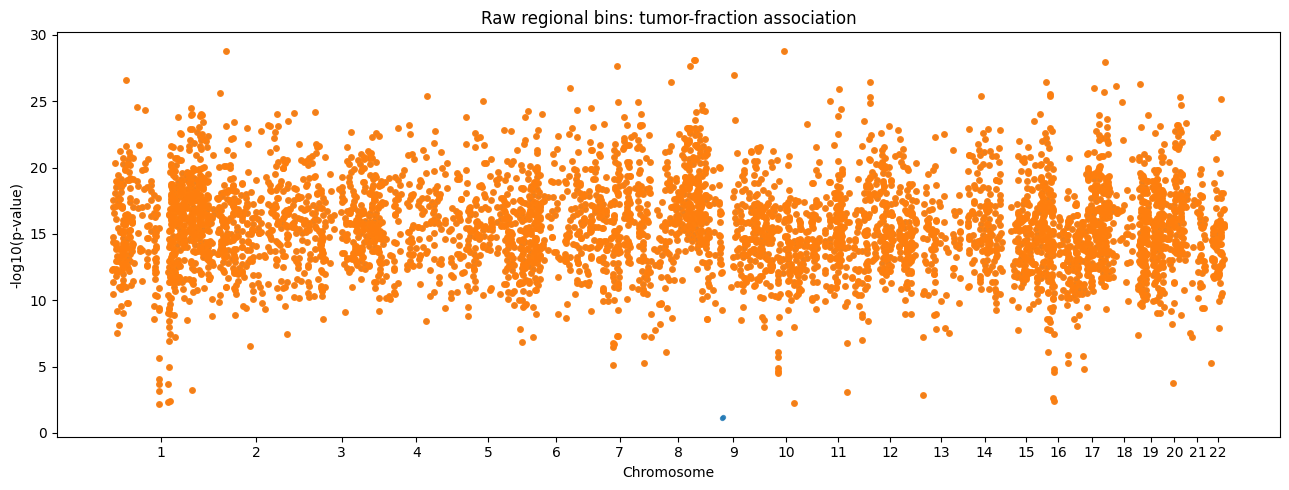

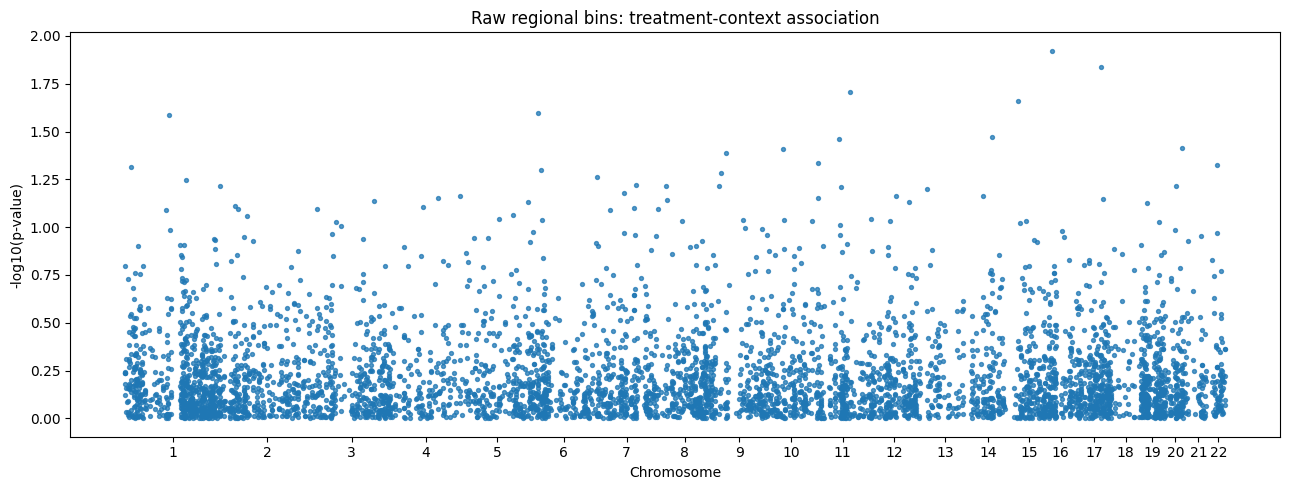

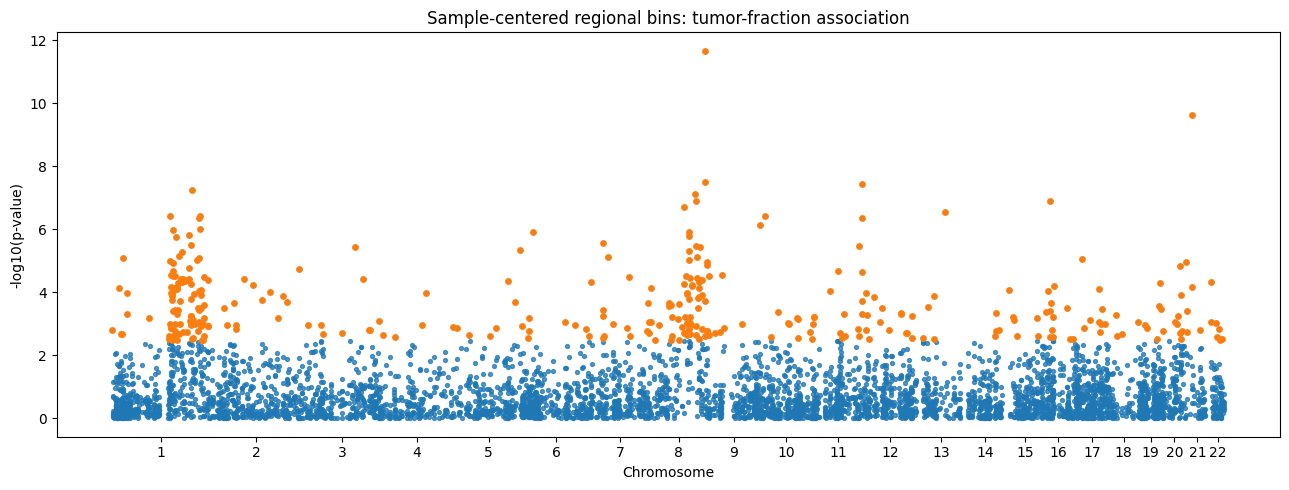

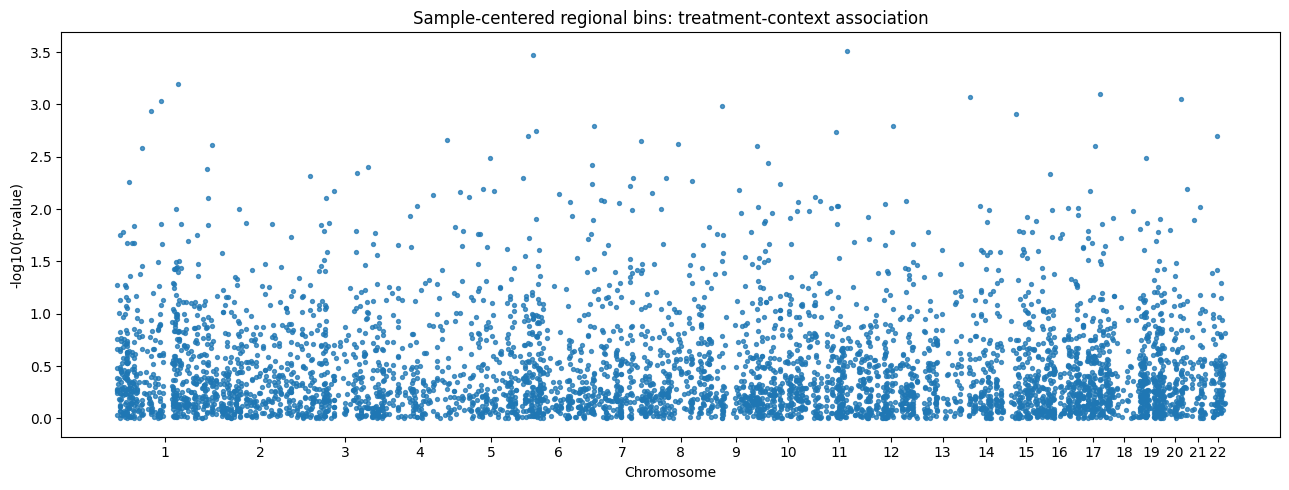

In [19]:

# ============================================================
# STEP 8: Generate Manhattan plots
# ============================================================

plot_manhattan(
    raw_results,
    p_col="p_tumor_fraction_percent",
    q_col="q_tumor_fraction_percent",
    path=STEP3_PLOT_DIR / "03_manhattan_raw_tumor_fraction_robust_screen.png",
    title="Raw regional bins: tumor-fraction association",
)

plot_manhattan(
    raw_results,
    p_col="p_treatment_overall",
    q_col="q_treatment_overall",
    path=STEP3_PLOT_DIR / "03_manhattan_raw_treatment_context_robust_screen.png",
    title="Raw regional bins: treatment-context association",
)

plot_manhattan(
    centered_results,
    p_col="p_tumor_fraction_percent",
    q_col="q_tumor_fraction_percent",
    path=STEP3_PLOT_DIR / "03_manhattan_sample_centered_tumor_fraction_robust_screen.png",
    title="Sample-centered regional bins: tumor-fraction association",
)

plot_manhattan(
    centered_results,
    p_col="p_treatment_overall",
    q_col="q_treatment_overall",
    path=STEP3_PLOT_DIR / "03_manhattan_sample_centered_treatment_context_robust_screen.png",
    title="Sample-centered regional bins: treatment-context association",
)


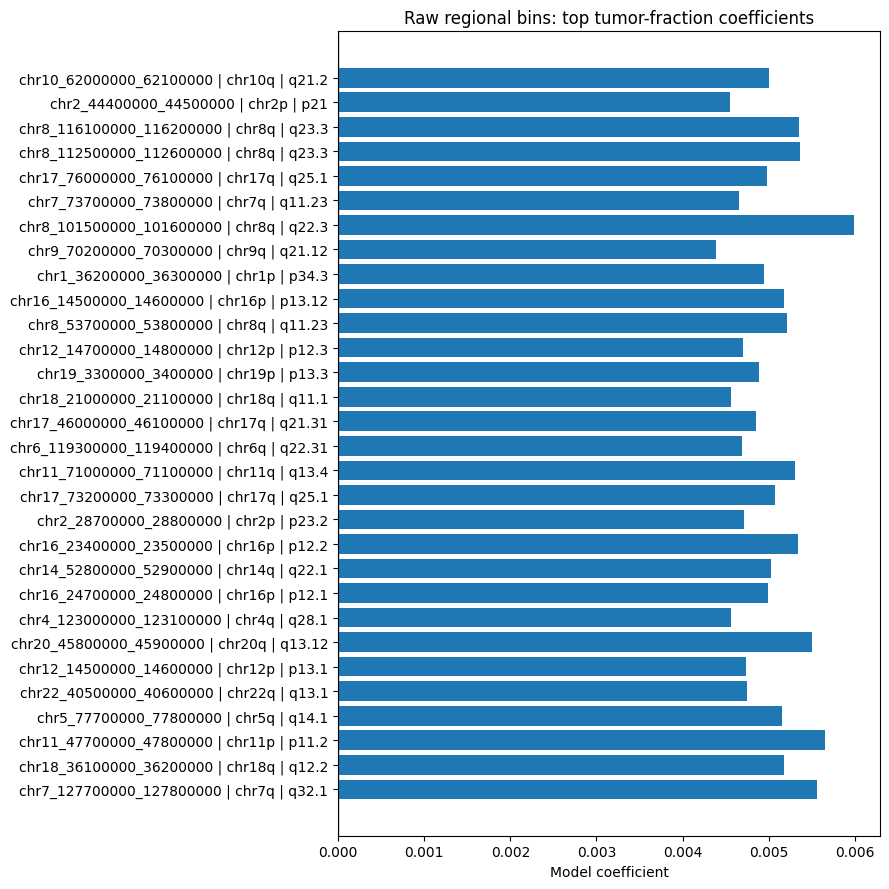

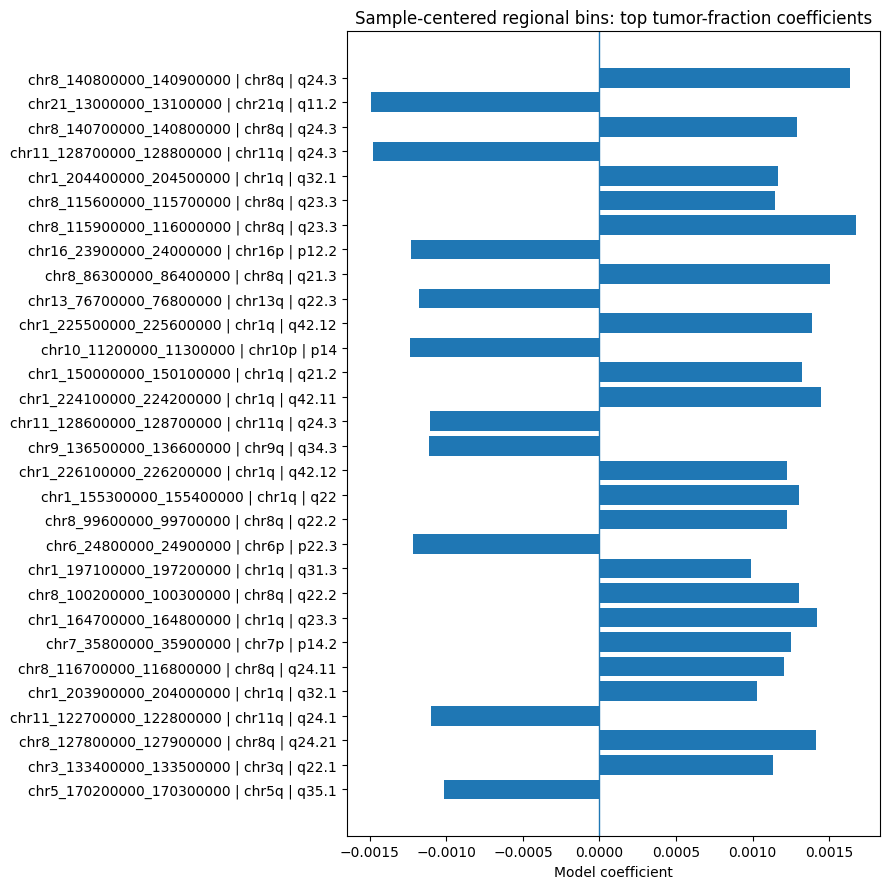

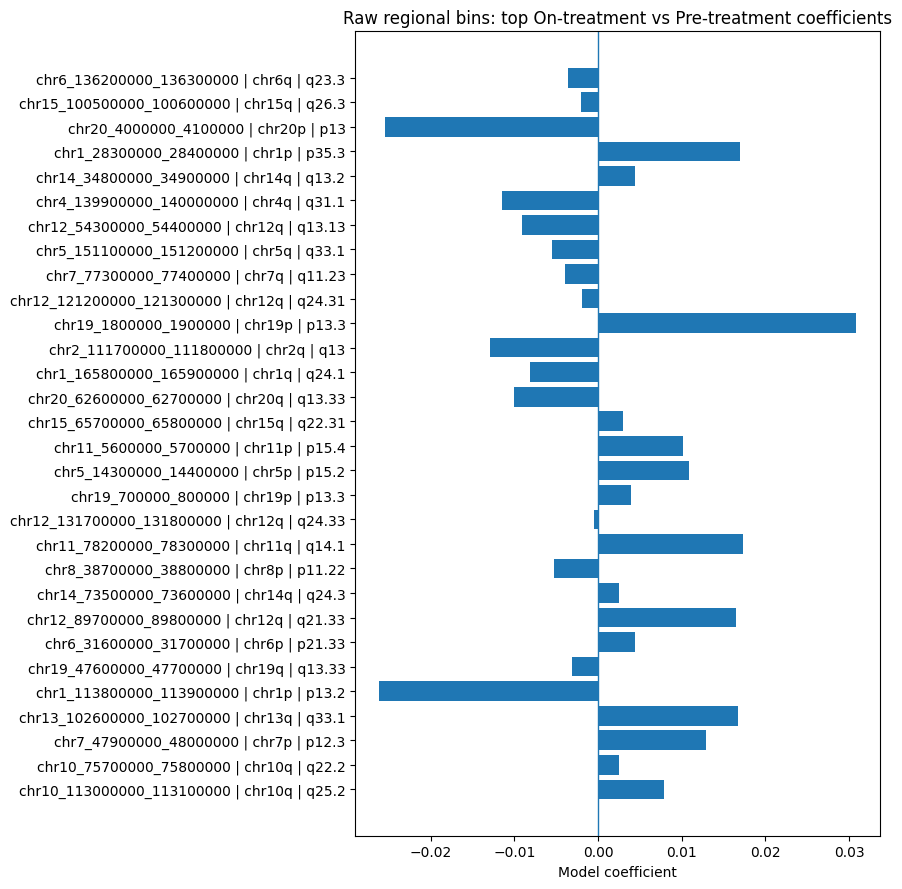

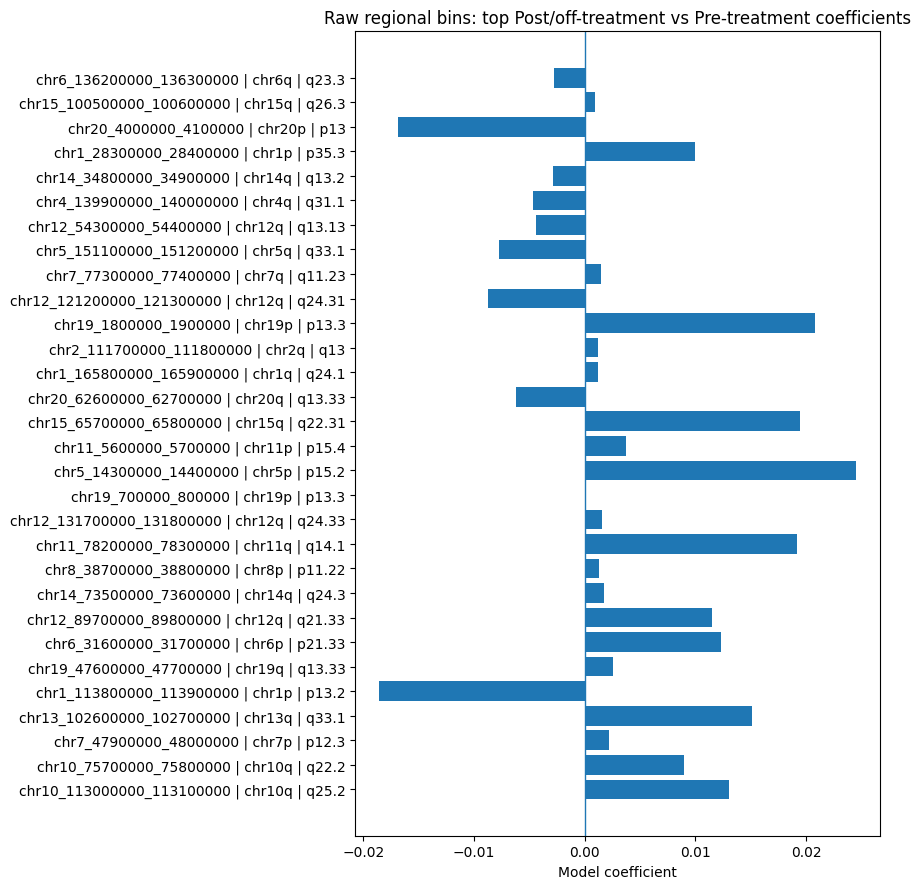

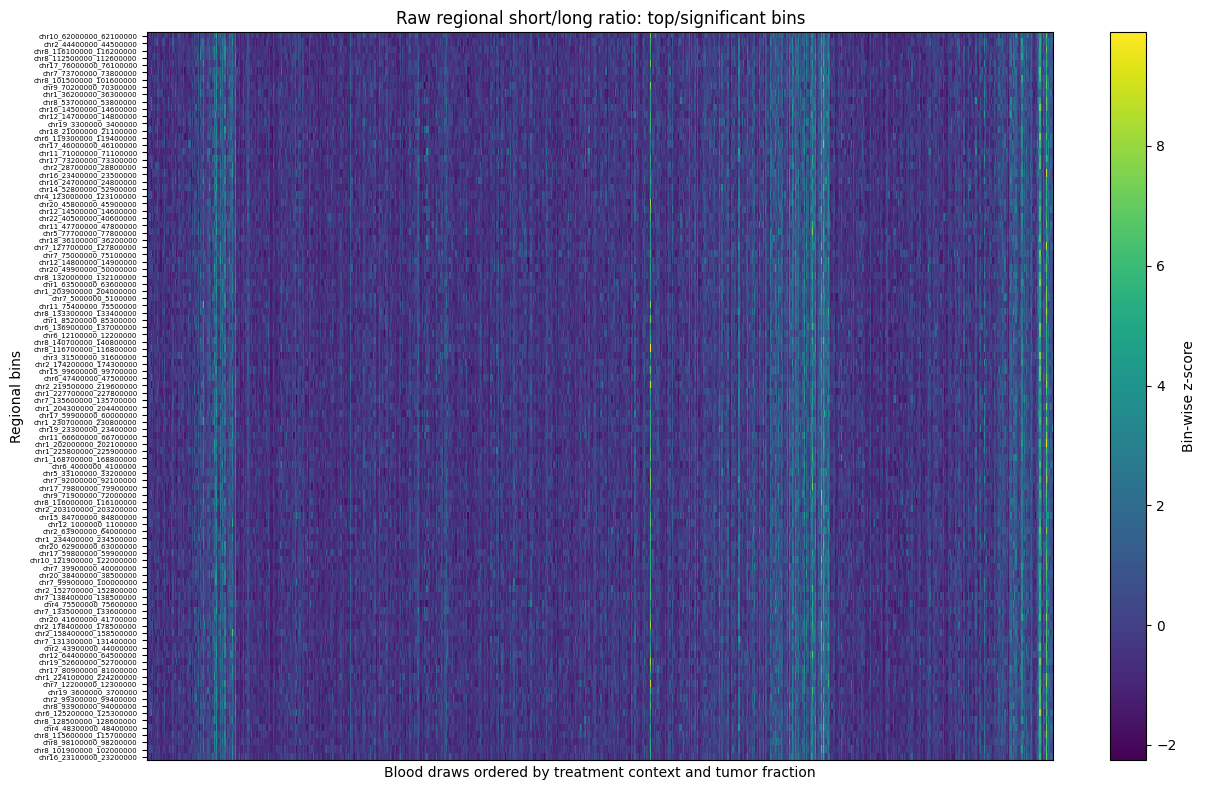

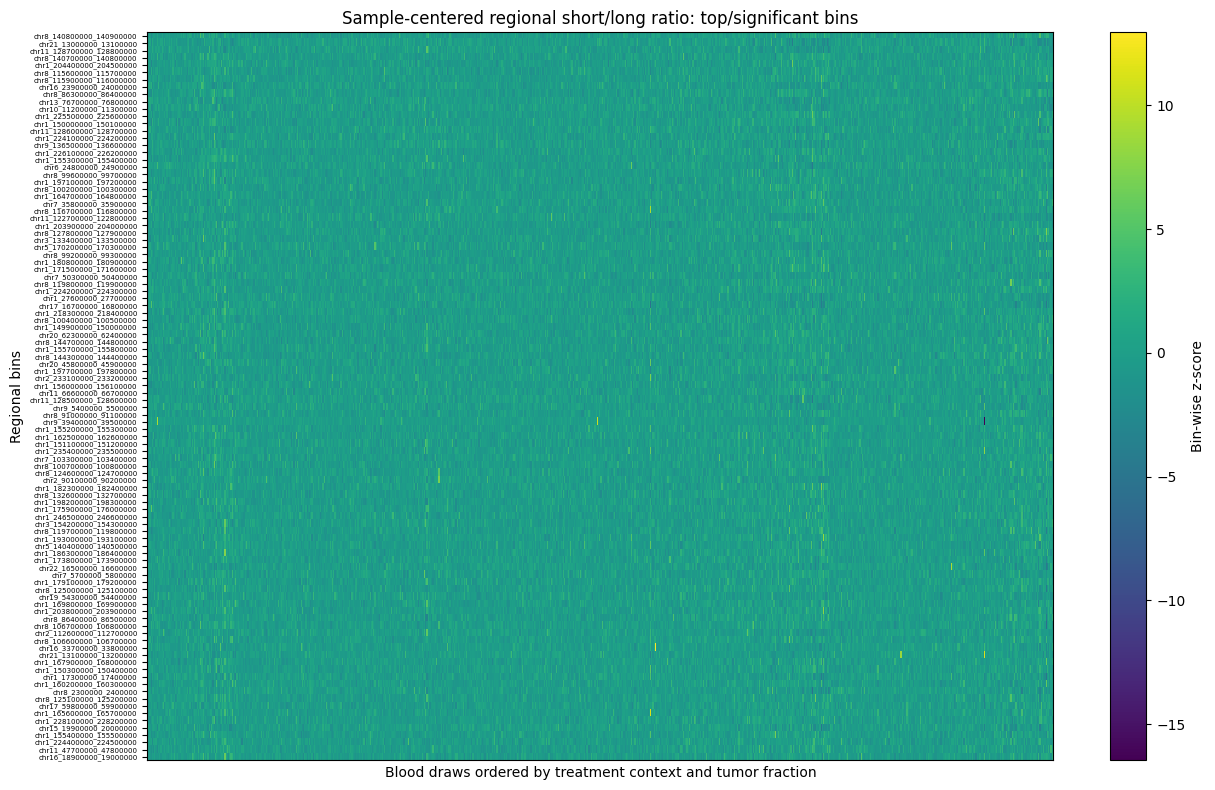

In [20]:

# ============================================================
# STEP 9: Generate coefficient plots and heatmaps
# ============================================================

plot_top_coefficients(
    raw_results,
    coef_col="coef_tumor_fraction_percent",
    q_col="q_tumor_fraction_percent",
    path=STEP3_PLOT_DIR / "03_top_raw_tumor_fraction_coefficients_robust_screen.png",
    title="Raw regional bins: top tumor-fraction coefficients",
    top_n=TOP_N_COEFFICIENT_PLOT,
)

plot_top_coefficients(
    centered_results,
    coef_col="coef_tumor_fraction_percent",
    q_col="q_tumor_fraction_percent",
    path=STEP3_PLOT_DIR / "03_top_sample_centered_tumor_fraction_coefficients_robust_screen.png",
    title="Sample-centered regional bins: top tumor-fraction coefficients",
    top_n=TOP_N_COEFFICIENT_PLOT,
)

plot_top_coefficients(
    raw_results,
    coef_col="coef_on_vs_pre",
    q_col="q_treatment_overall",
    path=STEP3_PLOT_DIR / "03_top_raw_on_vs_pre_coefficients_robust_screen.png",
    title="Raw regional bins: top On-treatment vs Pre-treatment coefficients",
    top_n=TOP_N_COEFFICIENT_PLOT,
)

plot_top_coefficients(
    raw_results,
    coef_col="coef_post_off_vs_pre",
    q_col="q_treatment_overall",
    path=STEP3_PLOT_DIR / "03_top_raw_post_off_vs_pre_coefficients_robust_screen.png",
    title="Raw regional bins: top Post/off-treatment vs Pre-treatment coefficients",
    top_n=TOP_N_COEFFICIENT_PLOT,
)

def select_heatmap_bins(results_df):
    bins = results_df.loc[
        results_df["q_tumor_fraction_percent"].lt(FDR_ALPHA)
        | results_df["q_treatment_overall"].lt(FDR_ALPHA),
        "bin",
    ].dropna().unique().tolist()

    if len(bins) == 0:
        tmp = results_df.copy()
        tmp["min_p"] = tmp[["p_tumor_fraction_percent", "p_treatment_overall"]].min(axis=1)
        bins = (
            tmp.sort_values("min_p")
            .head(TOP_N_HEATMAP_BINS)["bin"]
            .dropna()
            .tolist()
        )

    return bins

plot_top_bins_heatmap(
    X_matrix=X_raw,
    annot_df=analysis_ready,
    bins=select_heatmap_bins(raw_results),
    path=STEP3_PLOT_DIR / "03_heatmap_raw_top_or_significant_bins_robust_screen.png",
    title="Raw regional short/long ratio: top/significant bins",
    max_bins=TOP_N_HEATMAP_BINS,
)

plot_top_bins_heatmap(
    X_matrix=X_centered,
    annot_df=analysis_ready,
    bins=select_heatmap_bins(centered_results),
    path=STEP3_PLOT_DIR / "03_heatmap_sample_centered_top_or_significant_bins_robust_screen.png",
    title="Sample-centered regional short/long ratio: top/significant bins",
    max_bins=TOP_N_HEATMAP_BINS,
)


In [21]:

# ============================================================
# STEP 10: Save scientific notes
# ============================================================

notes = f"""
AURORA regional fragmentation Step 3 revised notes

Reason for revised Step 3:
Step 1 QC showed that some samples have very high regional SD but normal regional IQR.
This suggests that a small number of extreme bin values can inflate SD-based variability.
Therefore, the primary bin-level screen uses robust variability metrics and excludes bins
with implausibly extreme absolute log2(short/long) values.

Primary screen settings:
Selection metric: {SELECTION_METRIC}
Top variable bins per matrix: {TOP_N_VARIABLE_BINS}
Maximum allowed absolute bin value for primary screen: {MAX_ABS_VALUE_FOR_PRIMARY_SCREEN}
Model engine: {BIN_MODEL_ENGINE}
GEE sensitivity analysis: {RUN_GEE_SENSITIVITY}

Main model:
regional_short_long_ratio_bin ~ Treatment context + Tumor fraction (%)
clustered by Patient_Identifier

Treatment reference:
Pre-treatment

Interpretation:
Positive tumor-fraction coefficient:
Higher tumor fraction is associated with higher regional log2(short/long), consistent with relative
short-fragment enrichment in that bin.

Negative tumor-fraction coefficient:
Higher tumor fraction is associated with lower regional log2(short/long), consistent with relative
long-fragment enrichment or depletion of short fragments.

Caution:
Treatment-context bin-level findings should be considered exploratory unless they remain significant
after FDR correction and are robust to sample-centered analysis and/or GEE sensitivity analysis.

Recommended wording:
Regional fragmentation bins were screened using robust QC filtering and patient-clustered models adjusted
for tumor fraction and treatment context. Bins with implausibly extreme values were excluded from the
primary screen and saved for review. FDR correction was applied across tested bins. Significant bins were
interpreted as candidate regional fragmentation features for downstream biological annotation.

Output tables:
{STEP3_TABLE_DIR}

Output plots:
{STEP3_PLOT_DIR}
"""

notes_path = STEP3_TABLE_DIR / "03_revised_step3_scientific_notes.txt"
with open(notes_path, "w") as fh:
    fh.write(notes.strip() + "\n")

print(notes)
print("Saved:", notes_path)
print("Step 3 notebook completed:", time.ctime())



AURORA regional fragmentation Step 3 revised notes

Reason for revised Step 3:
Step 1 QC showed that some samples have very high regional SD but normal regional IQR.
This suggests that a small number of extreme bin values can inflate SD-based variability.
Therefore, the primary bin-level screen uses robust variability metrics and excludes bins
with implausibly extreme absolute log2(short/long) values.

Primary screen settings:
Selection metric: iqr
Top variable bins per matrix: 5000
Maximum allowed absolute bin value for primary screen: 10
Model engine: cluster_ols
GEE sensitivity analysis: True

Main model:
regional_short_long_ratio_bin ~ Treatment context + Tumor fraction (%)
clustered by Patient_Identifier

Treatment reference:
Pre-treatment

Interpretation:
Positive tumor-fraction coefficient:
Higher tumor fraction is associated with higher regional log2(short/long), consistent with relative
short-fragment enrichment in that bin.

Negative tumor-fraction coefficient:
Higher tumor 